<a href="https://colab.research.google.com/github/AlfCR/dnn-estadia/blob/main/notebooks/V_A_P_GRU.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Validación Cruzada - Modelo de GRU

In [2]:
#Celda 1
from google.colab import drive
drive.mount('/content/drive')

# Clonar el repositorio para traer el archivo modelos.py
!git clone https://github.com/AlfCR/dnn-estadia.git
%cd dnn-estadia
!git pull

import sys
sys.path.append('/content/dnn-estadia/src')
import numpy as np
import tensorflow as tf
from modelos import crear_modelo, obtener_callbacks
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

tf.random.set_seed(42)
np.random.seed(42)
print("Entorno de GRU configurado correctamente.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Cloning into 'dnn-estadia'...
remote: Enumerating objects: 89, done.
remote: Counting objects: 100% (89/89), done.
remote: Compressing objects: 100% (70/70), done.
remote: Total 89 (delta 31), reused 48 (delta 13), pack-reused 0 (from 0)
Receiving objects: 100% (89/89), 192.78 KiB | 2.41 MiB/s, done.
Resolving deltas: 100% (31/31), done.
/content/dnn-estadia/dnn-estadia
Already up to date.
Entorno de GRU configurado correctamente.


In [4]:
#Celda 2 CARGAR EL DATASET

ruta = '/content/drive/MyDrive/Colab Notebooks/dataset/dataset_limpio/dataset_preparado_3d.npz'
datos = np.load(ruta)
X_train = datos['X_train']
y_train = datos['y_train']

X_val = datos['X_val']
y_val = datos['y_val']

X_test = datos['X_test']
y_test = datos['y_test']

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (6959, 30, 23)
y_train: (6959,)
X_val: (1343, 30, 23)
y_val: (1343,)
X_test: (2342, 30, 23)
y_test: (2342,)


In [8]:
# Celda 3
tscv = TimeSeriesSplit(n_splits=5) #Validaciones independientes (5)

for fold, (train_idx, val_idx) in enumerate(
        tscv.split(X_train),
        start=1):

    print(f"\n FOLD {fold} ")

    print("Primer índice train:", train_idx[0])
    print("Último índice train:", train_idx[-1])

    print("Primer índice val:", val_idx[0])
    print("Último índice val:", val_idx[-1])

    print("Tamaño train:", len(train_idx))
    print("Tamaño val:", len(val_idx))


 FOLD 1 
Primer índice train: 0
Último índice train: 1163
Primer índice val: 1164
Último índice val: 2322
Tamaño train: 1164
Tamaño val: 1159

 FOLD 2 
Primer índice train: 0
Último índice train: 2322
Primer índice val: 2323
Último índice val: 3481
Tamaño train: 2323
Tamaño val: 1159

 FOLD 3 
Primer índice train: 0
Último índice train: 3481
Primer índice val: 3482
Último índice val: 4640
Tamaño train: 3482
Tamaño val: 1159

 FOLD 4 
Primer índice train: 0
Último índice train: 4640
Primer índice val: 4641
Último índice val: 5799
Tamaño train: 4641
Tamaño val: 1159

 FOLD 5 
Primer índice train: 0
Último índice train: 5799
Primer índice val: 5800
Último índice val: 6958
Tamaño train: 5800
Tamaño val: 1159


In [11]:
# Celda 4 PRIMER ENTRENAMIENTO DENTRO DE LOS FOLDS

rmse_folds = []
mae_folds = []
r2_folds = []

for fold, (train_idx, val_idx) in enumerate(tscv.split(X_train),start=1):

    print(f"\n FOLD {fold} ")

    X_tr = X_train[train_idx]
    y_tr = y_train[train_idx]

    X_val_fold = X_train[val_idx]
    y_val_fold = y_train[val_idx]

    modelo = crear_modelo(tipo = 'GRU')


    modelo.fit(X_tr, y_tr, epochs=100, batch_size=64, validation_data=(X_val_fold, y_val_fold), callbacks=obtener_callbacks(), verbose=0)

    y_pred = modelo.predict(X_val_fold, verbose=0).flatten()

    rmse = np.sqrt(mean_squared_error(y_val_fold, y_pred))
    rmse_folds.append(rmse)

    mae = mean_absolute_error(y_val_fold, y_pred)
    mae_folds.append(mae)

    r2 = r2_score(y_val_fold, y_pred)
    r2_folds.append(r2)

    print(f"RMSE: {rmse:.4f}")
    print(f"MAE: {mae:.4f}")
    print(f"R2: {r2:.4f}")



 FOLD 1 
Epoch 16: early stopping
Restoring model weights from the end of the best epoch: 6.
RMSE: 0.8926
MAE: 0.6343
R2: 0.4171

 FOLD 2 
Epoch 26: early stopping
Restoring model weights from the end of the best epoch: 16.
RMSE: 0.6779
MAE: 0.5095
R2: 0.3571

 FOLD 3 
Epoch 21: early stopping
Restoring model weights from the end of the best epoch: 11.
RMSE: 0.8012
MAE: 0.5593
R2: 0.3152

 FOLD 4 
Epoch 13: early stopping
Restoring model weights from the end of the best epoch: 3.
RMSE: 0.7501
MAE: 0.5474
R2: 0.2648

 FOLD 5 
Epoch 18: early stopping
Restoring model weights from the end of the best epoch: 8.
RMSE: 0.8239
MAE: 0.5713
R2: 0.4393


In [12]:
print("\nRESULTADOS")

print(f"RMSE promedio: {np.mean(rmse_folds):.4f}")
print(f"RMSE std: {np.std(rmse_folds):.4f}")

print(f"MAE promedio: {np.mean(mae_folds):.4f}")
print(f"MAE std: {np.std(mae_folds):.4f}")

print(f"R² promedio: {np.mean(r2_folds):.4f}")
print(f"R² std: {np.std(r2_folds):.4f}")


RESULTADOS
RMSE promedio: 0.7891
RMSE std: 0.0720
MAE promedio: 0.5644
MAE std: 0.0406
R² promedio: 0.3587
R² std: 0.0642


In [13]:
import os
import pandas as pd

# 1. Definir la ruta de destino
directorio_destino = '/content/drive/MyDrive/Colab Notebooks/dataset/v_a_p_GRU'
os.makedirs(directorio_destino, exist_ok=True)
ruta_archivo = os.path.join(directorio_destino, 'resultados_gru.csv')

# 2. Estructurar los datos de los folds
data = {
    'Fold': [f'Fold {i}' for i in range(1, len(rmse_folds) + 1)],
    'RMSE': [float(r) for r in rmse_folds],
    'MAE': [float(m) for m in mae_folds],
    'R2': [float(r) for r in r2_folds]
}

# Crear el DataFrame inicial
df_resultados = pd.DataFrame(data)

# 3. Calcular filas adicionales para Promedio y Desviación Estándar
fila_promedio = {
    'Fold': 'Promedio',
    'RMSE': round(np.mean(rmse_folds), 4),
    'MAE': round(np.mean(mae_folds), 4),
    'R2': round(np.mean(r2_folds), 4),
}

fila_std = {
    'Fold': 'Desviación Estándar',
    'RMSE': round(np.std(rmse_folds), 4),
    'MAE': round(np.std(mae_folds), 4),
    'R2': round(np.std(r2_folds), 4),
}

# Añadir las filas al DataFrame
df_resultados = pd.concat([df_resultados, pd.DataFrame([fila_promedio, fila_std])], ignore_index=True)

# Datos en excel
ruta_excel = os.path.join(directorio_destino, 'resultados_gru.xlsx')
df_resultados.to_excel(ruta_excel, index=False)
print(f"Tabla de resultados guardada exitosamente en:\n{ruta_excel}\n")


# 4. Guardar a CSV e imprimir para visualizar en el cuaderno
df_resultados.to_csv(ruta_archivo, index=False)
print(f"Tabla de resultados guardada exitosamente en:\n{ruta_archivo}\n")
display(df_resultados)

Tabla de resultados guardada exitosamente en:
/content/drive/MyDrive/Colab Notebooks/dataset/v_a_p_GRU/resultados_gru.xlsx

Tabla de resultados guardada exitosamente en:
/content/drive/MyDrive/Colab Notebooks/dataset/v_a_p_GRU/resultados_gru.csv



,Fold,RMSE,MAE,R2
0,Fold 1,0.892563,0.634271,0.417135
1,Fold 2,0.677909,0.509536,0.357111
2,Fold 3,0.801151,0.559326,0.315183
3,Fold 4,0.750149,0.547413,0.264828
4,Fold 5,0.823929,0.571275,0.439259
5,Promedio,0.789100,0.564400,0.358700
6,Desviación Estándar,0.072000,0.040600,0.064200


Gráfica guardada exitosamente en:
/content/drive/MyDrive/Colab Notebooks/dataset/v_a_p_GRU/grafica_rmse_folds.png



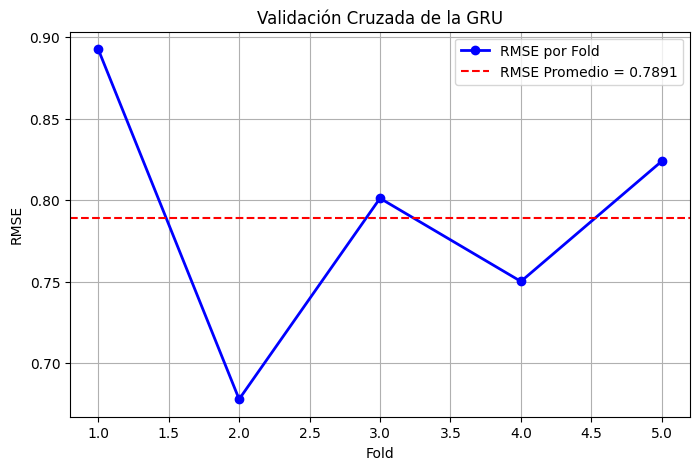

In [15]:
import os
import matplotlib.pyplot as plt

directorio_destino = '/content/drive/MyDrive/Colab Notebooks/dataset/v_a_p_GRU'
os.makedirs(directorio_destino, exist_ok=True)


plt.figure(figsize=(8, 5))

plt.plot(
    [1, 2, 3, 4, 5],
    rmse_folds,
    marker='o',
    linewidth=2,
    color='blue',
    label='RMSE por Fold'
)

plt.axhline(
    np.mean(rmse_folds),
    color='red',
    linestyle='--',
    label=f'RMSE Promedio = {np.mean(rmse_folds):.4f}'
)

plt.title('Validación Cruzada de la GRU')
plt.xlabel('Fold')
plt.ylabel('RMSE')
plt.grid(True)
plt.legend()

ruta_grafica = os.path.join(directorio_destino, 'grafica_rmse_folds.png')
plt.savefig(ruta_grafica, dpi=300, bbox_inches='tight')
print(f"Gráfica guardada exitosamente en:\n{ruta_grafica}\n")

plt.show()

##Conclusiones
